# Decision Tree Classifier
- Same as regressor BUT predicts a CLASS not a number
- Splits using Gini or Entropy (not variance)
- Leaf prediction = majority class (not mean)
- Dataset: Breast Cancer (569 patients, 30 features, 2 classes)
- Goal: predict malignant vs benign

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay)

In [2]:
data = load_breast_cancer()
X, y = data.data, data.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)

## 1. How a split is chosen: Gini, Entropy, Information Gain (manual calculation)

In [3]:
def gini(labels):
    _, c = np.unique(labels, return_counts=True) #np.unique → finds unique values + how many times each appears
    p = c / c.sum() #Convert counts to probabilities
    return 1 - (p ** 2).sum()

def entropy(labels):
    _, c = np.unique(labels, return_counts=True) #Entropy formula: −Σ p × log₂(p), Measures how mixed up the labels are
    p = c / c.sum()
    return -(p * np.log2(p)).sum()

def information_gain(parent, left, right):
    n = len(parent)
    return entropy(parent) - (len(left) / n) * entropy(left) - (len(right) / n) * entropy(right)

feature = 0  # mean radius
thr = np.median(X_train[:, feature])
left, right = y_train[X_train[:, feature] <= thr], y_train[X_train[:, feature] > thr]
print(f"Parent  gini={gini(y_train):.3f} entropy={entropy(y_train):.3f}")
print(f"Split on '{data.feature_names[feature]}' <= {thr:.2f}")
print(f"Information gain = {information_gain(y_train, left, right):.4f}")

Parent  gini=0.468 entropy=0.953
Split on 'mean radius' <= 13.27
Information gain = 0.3382


## 2. Gini vs Entropy

In [4]:
for crit in ["gini", "entropy"]:
    m = DecisionTreeClassifier(criterion=crit, random_state=0).fit(X_train, y_train)
    print(f"{crit:8s} -> train acc={m.score(X_train, y_train):.3f} | test acc={m.score(X_test, y_test):.3f} | depth={m.get_depth()} leaves={m.get_n_leaves()}")

gini     -> train acc=1.000 | test acc=0.937 | depth=7 leaves=18
entropy  -> train acc=1.000 | test acc=0.944 | depth=6 leaves=15


## 3. Overfitting: accuracy vs tree depth

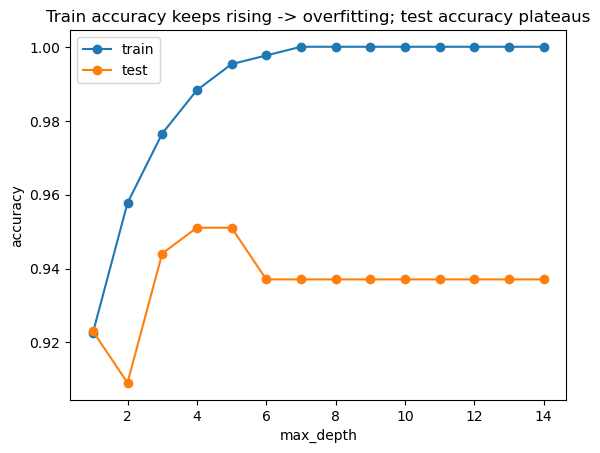

In [5]:
depths = range(1, 15)
tr, te = [], []
for d in depths:
    m = DecisionTreeClassifier(max_depth=d, random_state=0).fit(X_train, y_train)
    tr.append(m.score(X_train, y_train)); te.append(m.score(X_test, y_test))
plt.plot(depths, tr, "o-", label="train"); plt.plot(depths, te, "o-", label="test")
plt.xlabel("max_depth"); plt.ylabel("accuracy"); plt.legend()
plt.title("Train accuracy keeps rising -> overfitting; test accuracy plateaus")
plt.show()

## Impurity + Information Gain
- Gini = 1 − Σ(p²)  → faster, default
- Entropy = −Σ p×log₂(p)  → slightly slower
- Both = 0 means pure node (perfect split result)
- Information Gain = entropy before − weighted entropy after
- Tree picks split with HIGHEST information gain at every node
- Gini ≈ Entropy in practice, Gini is faster

## 4. Pruning: pre-pruning (GridSearch) + post-pruning (ccp_alpha)

Pre-pruning  = stop the tree from growing too big
               (set rules BEFORE training)

Post-pruning = let tree grow fully, THEN cut weak branches
               (ccp_alpha does this)

In [6]:
grid = GridSearchCV(DecisionTreeClassifier(random_state=0),
                    {"criterion": ["gini", "entropy"], "max_depth": [2, 3, 4, 5, 6, None],
                     "min_samples_leaf": [1, 3, 5, 10], "ccp_alpha": [0, 0.005, 0.01, 0.02]},
                    cv=5, scoring="accuracy").fit(X_train, y_train)
print("Best params:", grid.best_params_, "| CV acc:", round(grid.best_score_, 4))
best = grid.best_estimator_

Best params: {'ccp_alpha': 0, 'criterion': 'entropy', 'max_depth': None, 'min_samples_leaf': 1} | CV acc: 0.9508


## Pruning
- Pre-pruning: max_depth, min_samples_leaf → stops early
- Post-pruning: ccp_alpha → grows full tree then cuts weak branches
- Higher ccp_alpha → simpler tree
- GridSearchCV tries 192 combos × 5 folds = 960 fits
- scoring="accuracy" for classification (not neg_MSE)

## 5. Evaluation: confusion matrix and report

Test accuracy: 0.9441
              precision    recall  f1-score   support

   malignant       0.91      0.94      0.93        53
      benign       0.97      0.94      0.96        90

    accuracy                           0.94       143
   macro avg       0.94      0.94      0.94       143
weighted avg       0.94      0.94      0.94       143

Confusion matrix:
 [[50  3]
 [ 5 85]]


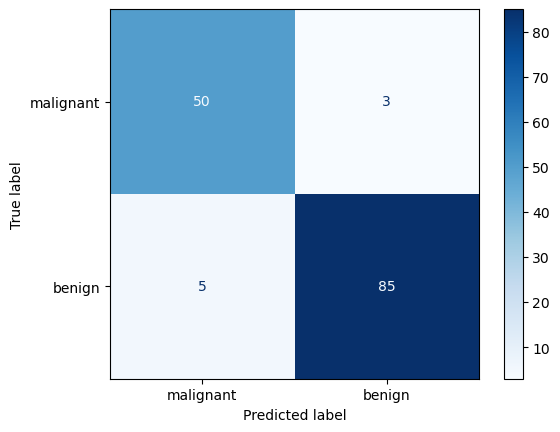

In [7]:
y_pred = best.predict(X_test)
print("Test accuracy:", round(accuracy_score(y_test, y_pred), 4))
print(classification_report(y_test, y_pred, target_names=data.target_names))
cm = confusion_matrix(y_test, y_pred)
print("Confusion matrix:\n", cm)
ConfusionMatrixDisplay(cm, display_labels=data.target_names).plot(cmap="Blues")
plt.show()

## 6. Visualize the pruned tree and feature importance

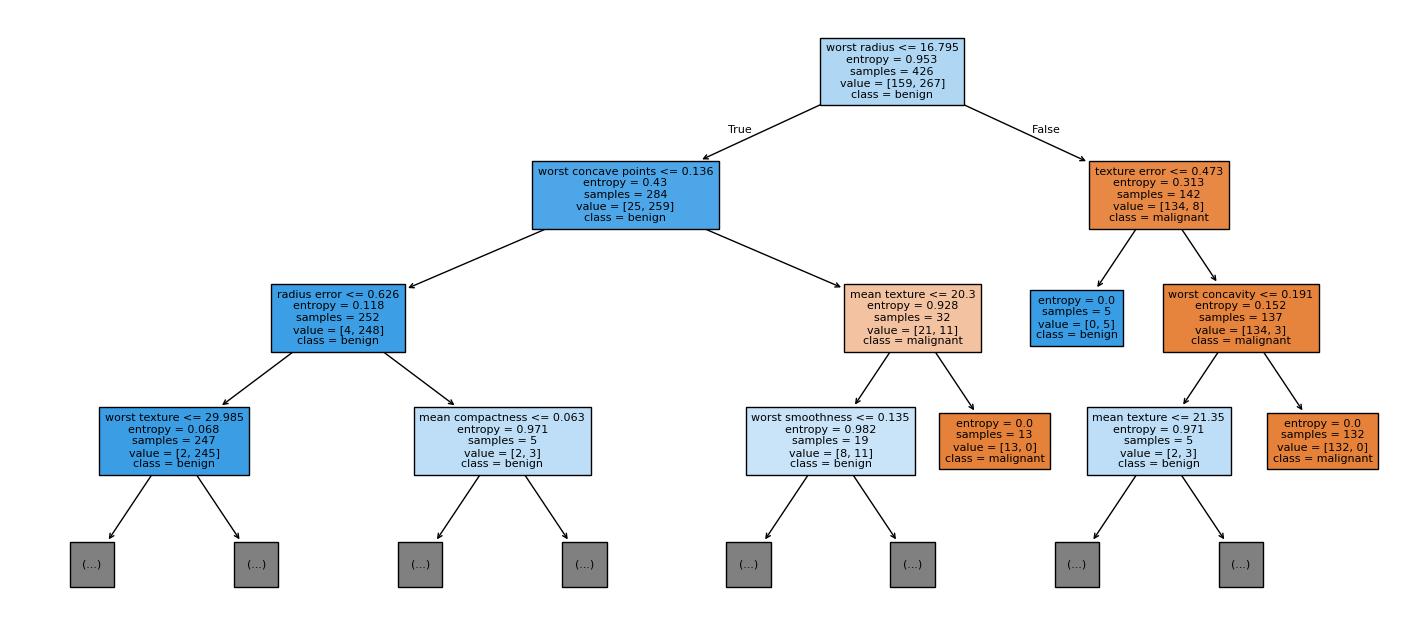

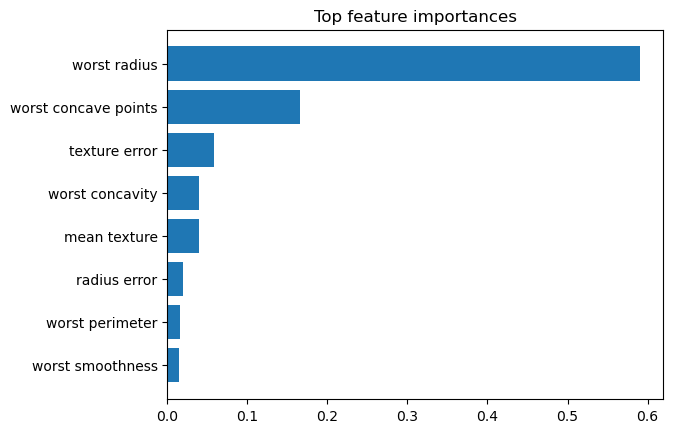

In [8]:
plt.figure(figsize=(18, 8))
plot_tree(best, feature_names=data.feature_names, class_names=data.target_names, filled=True, max_depth=3, fontsize=8)
plt.show()

imp = best.feature_importances_
idx = np.argsort(imp)[-8:]
plt.barh(data.feature_names[idx], imp[idx]); plt.title("Top feature importances")
plt.show()

PRUNING:
  pre  → max_depth, min_samples_leaf (set before training)
  post → ccp_alpha (grow full, then cut)
  both → GridSearchCV finds best combo

EVALUATION:
  precision → quality of positive predictions
  recall    → coverage of actual positives
  f1        → balance of both
  Medical → always prioritize recall

CONFUSION MATRIX:
  diagonal     = correct
  top-right    = false negatives (dangerous in medical)
  bottom-left  = false positives (less dangerous)

FEATURE IMPORTANCE:
  measures impurity reduction per feature
  top feature = used at root (most important split)
  sums to 1.0

Data (breast cancer, 30 features)
        ↓
Gini/Entropy/IG   → understand HOW splits are chosen
        ↓
depth experiment  → see train↑ test plateaus → find sweet spot
        ↓
GridSearchCV      → find best depth + leaf size + ccp_alpha
        ↓
classification_report → precision, recall, f1 per class
confusion matrix      → see exactly which mistakes were made
        ↓
plot_tree             → see the actual decision rules
feature_importances_  → which features drove the decisions